In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# load data
df = pd.read_csv("../heart.csv")

df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


#### Highly experimental code, keep the amount of suspected columns to 5 or less (or prepare for a longer processing time)
This tool combines box plots and scatterplots for detecting overlapping. Pretty neat!

It seems this tool is mostly useful with continuous variables. Categoricals get on top of each other, making the scatterlpots for them useless.

## NEW COMPARISON ## - Cholesterol vs HeartDisease


<Figure size 1000x600 with 0 Axes>

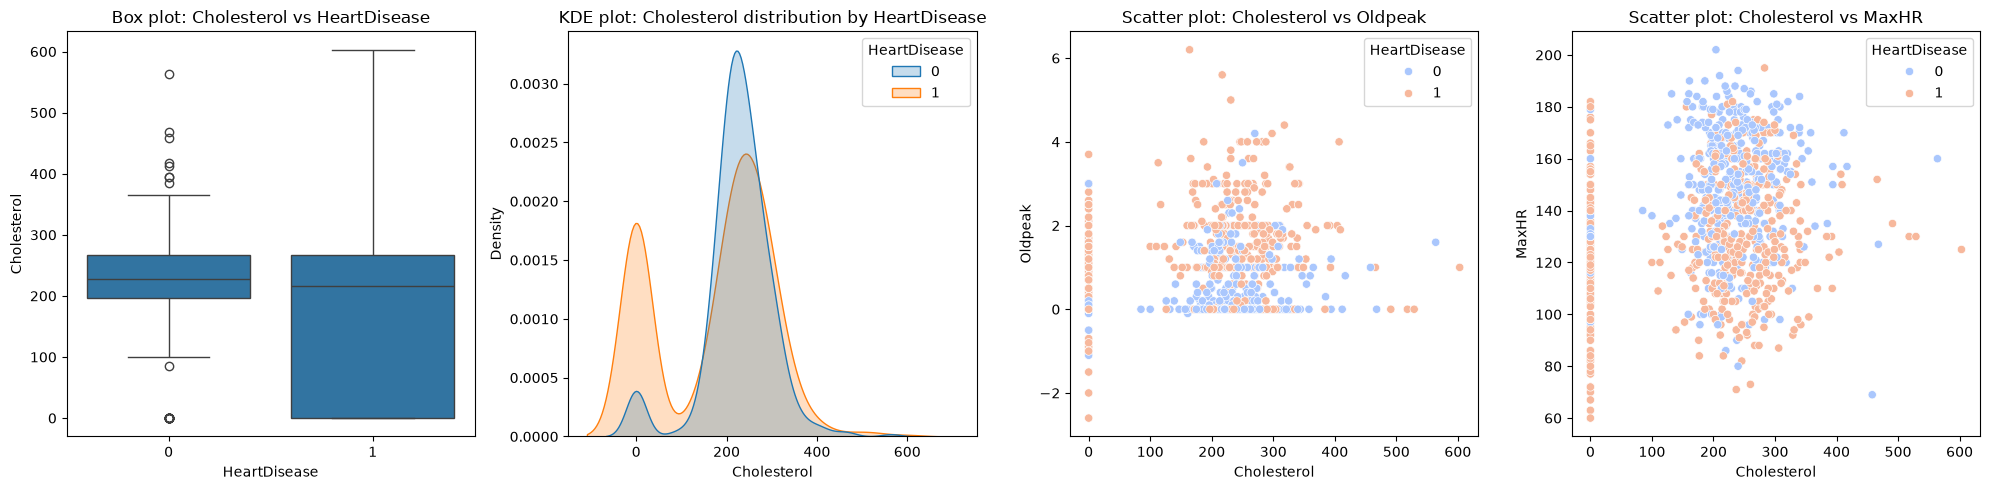

## NEW COMPARISON ## - Oldpeak vs HeartDisease


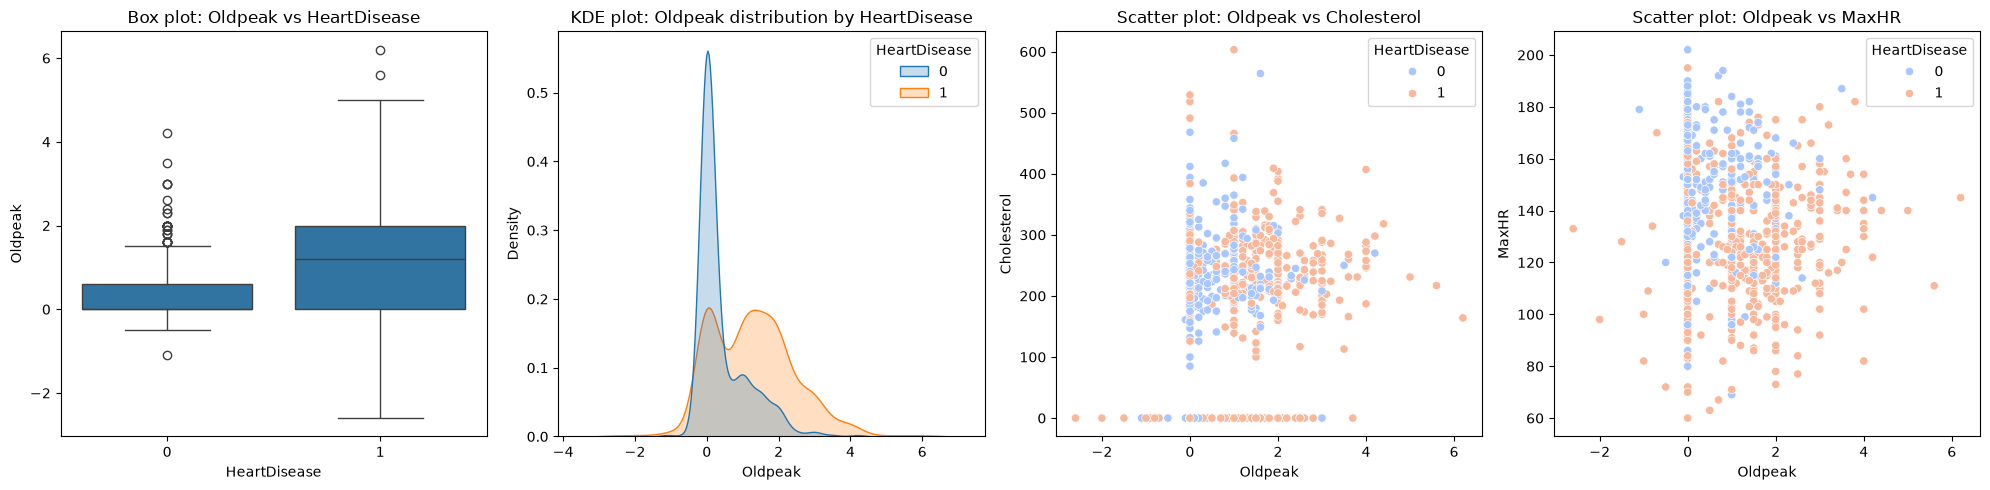

## NEW COMPARISON ## - MaxHR vs HeartDisease


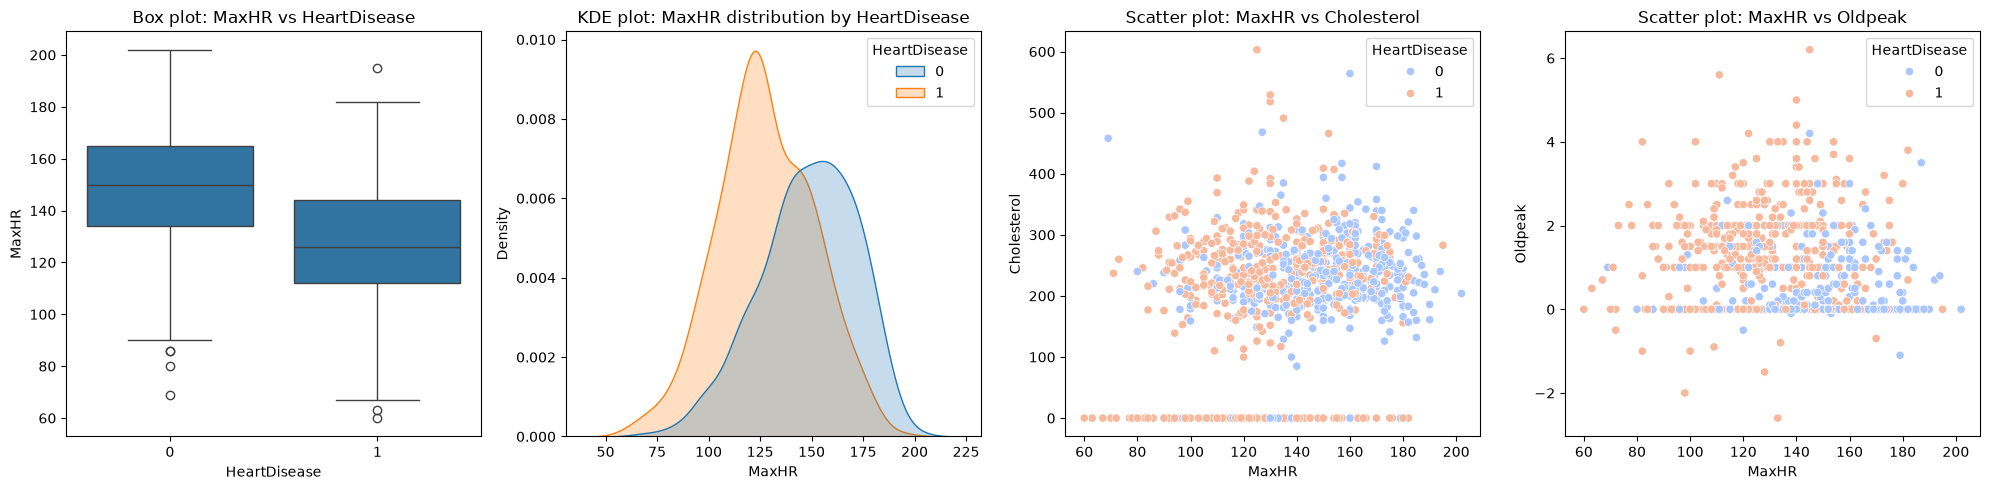

In [4]:
# CODE PARTIALLY GENERATED BY CHATGPT
# modified by instructor to have more features and small finetuning for presentation

# List of suspected columns for overlap
# USE SHAP, LIME, phik-matrix, correlation matrix etc to find columns that seems
# probable for having overlap, noise, redundancy, distribution problems and/or outlier problems
# try to keep the amount of variables to a small number at a time, so you don't slow down the
# process of plot generation below
suspected_columns = ['Cholesterol', 'Oldpeak', 'MaxHR']
target_variable = 'HeartDisease'  # The target variable

# Plot size settings
plt.figure(figsize=(10, 6))

# Iterate through suspected columns to generate box plots and scatter plots in a horizontal layout
for feature in suspected_columns:
    print(f"## NEW COMPARISON ## - {feature} vs {target_variable}")
    num_other_features = len([col for col in suspected_columns if col != feature])
    
    # Create a horizontal grid with 1 row and (1 + num_other_features + 1) columns
    fig, axes = plt.subplots(1, 2 + num_other_features, figsize=(5 * (2 + num_other_features), 5))
    
    # First plot: Box plot for the feature against the target variable
    sns.boxplot(x=target_variable, y=feature, data=df, ax=axes[0])
    axes[0].set_title(f'Box plot: {feature} vs {target_variable}')
    
    # Second plot: KDE plot for the feature, showing distribution by target variable
    sns.kdeplot(x=feature, hue=target_variable, data=df, fill=True, ax=axes[1])
    axes[1].set_title(f'KDE plot: {feature} distribution by {target_variable}')
    
    # Remaining plots: Scatter plots for the feature against every other feature
    for i, other_feature in enumerate([col for col in suspected_columns if col != feature]):
        sns.scatterplot(x=feature, palette="coolwarm", y=other_feature, hue=target_variable, data=df, ax=axes[i + 2])
        axes[i + 2].set_title(f'Scatter plot: {feature} vs {other_feature}')
    
    # Display the entire row of plots
    plt.tight_layout()
    plt.show()

#### From this section onward - experimentation with visualizations
Some parts done with ChatGPT + heavy modifications

Let's use seaborn for overlap detection...

<Axes: xlabel='HeartDisease', ylabel='Oldpeak'>

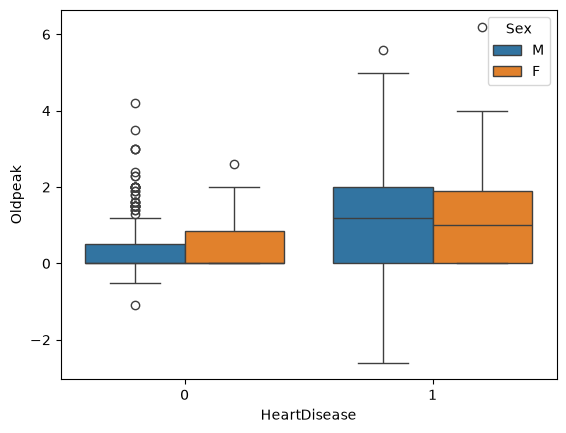

In [5]:
sns.boxplot(x="HeartDisease", y="Oldpeak", data=df, hue="Sex")

<Axes: xlabel='HeartDisease', ylabel='Oldpeak'>

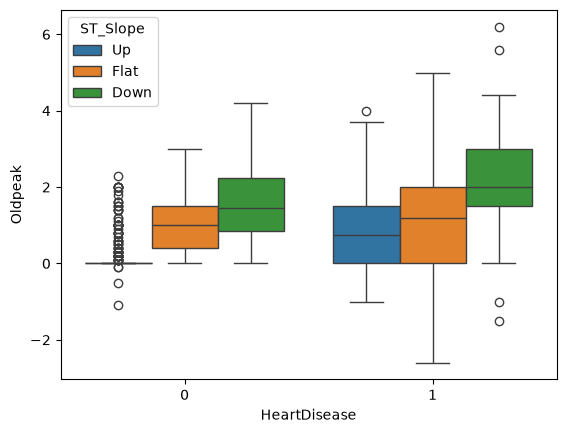

In [6]:
sns.boxplot(x="HeartDisease", y="Oldpeak", data=df, hue="ST_Slope")

<Axes: xlabel='HeartDisease', ylabel='MaxHR'>

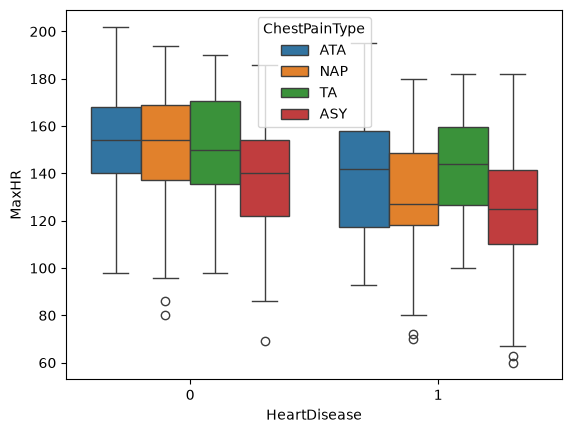

In [7]:
sns.boxplot(x="HeartDisease", y="MaxHR", data=df, hue="ChestPainType")

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

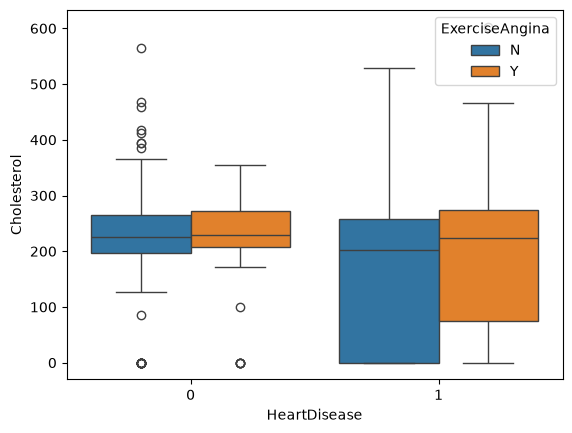

In [8]:
sns.boxplot(x="HeartDisease", y="Cholesterol", data=df, hue="ExerciseAngina")

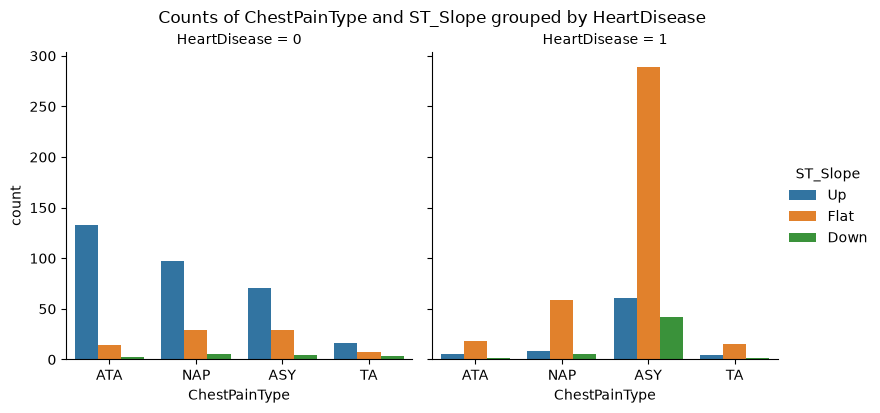

In [9]:
sns.catplot(
    data=df,
    x='ChestPainType',
    hue='ST_Slope',
    col='HeartDisease',      # one subplot per target class
    kind='count',
    height=4,
    aspect=1
)

plt.suptitle("Counts of ChestPainType and ST_Slope grouped by HeartDisease", y=1.02)
plt.show()

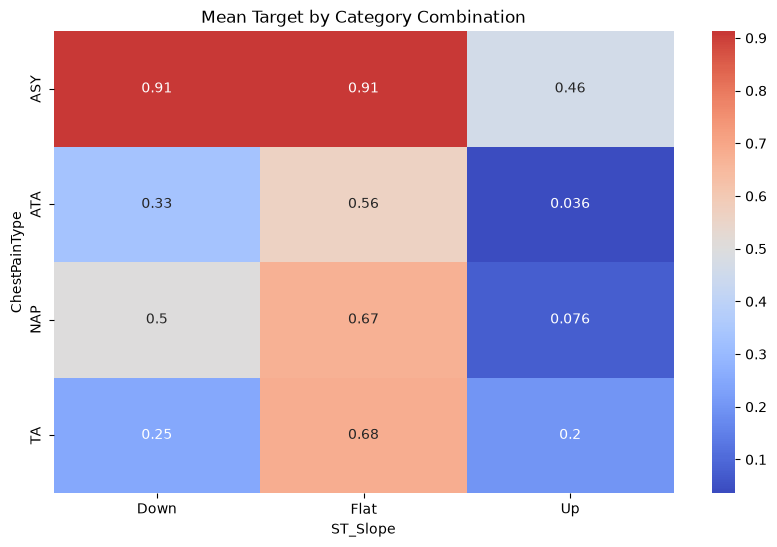

In [10]:
pivot = df.pivot_table(index='ChestPainType', columns='ST_Slope', values='HeartDisease', aggfunc='mean')

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, cmap='coolwarm', center=0.5)  # center on mid-point of 0-1
plt.title('Mean Target by Category Combination')
plt.show()

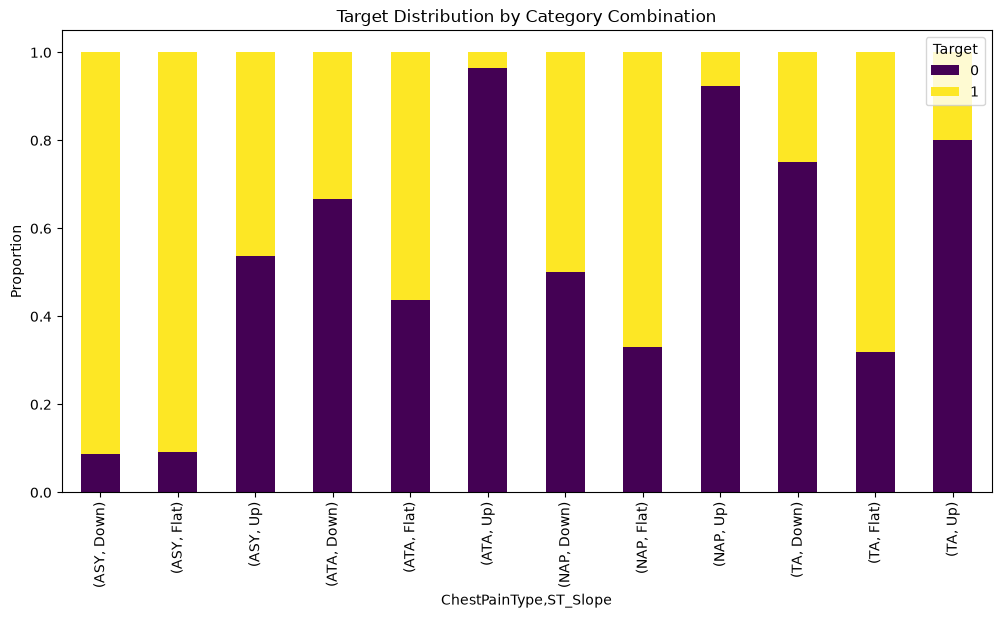

In [11]:
group = df.groupby(['ChestPainType', 'ST_Slope'])['HeartDisease'].value_counts(normalize=True).unstack().fillna(0)

group.plot(kind='bar', stacked=True, colormap='viridis', figsize=(12, 6))
plt.ylabel('Proportion')
plt.title('Target Distribution by Category Combination')
plt.legend(title='Target')
plt.show()

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

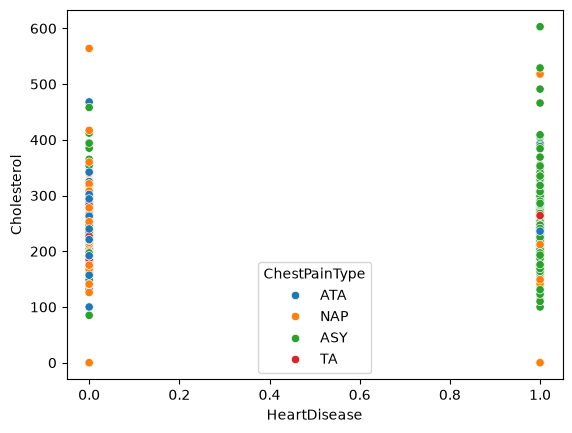

In [12]:
sns.scatterplot(x="HeartDisease", y="Cholesterol", hue="ChestPainType", data=df)

<Axes: xlabel='HeartDisease', ylabel='Oldpeak'>

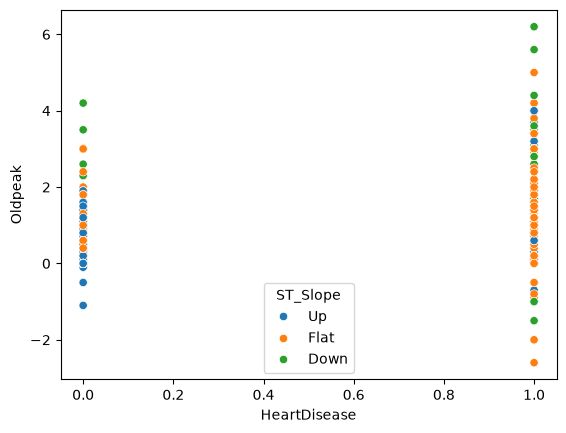

In [13]:
sns.scatterplot(x="HeartDisease", y="Oldpeak", hue="ST_Slope", data=df)

<Axes: xlabel='HeartDisease', ylabel='MaxHR'>

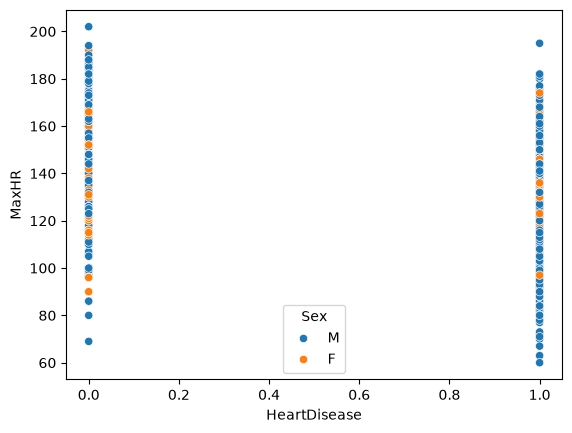

In [14]:
sns.scatterplot(x="HeartDisease", y="MaxHR", hue="Sex", data=df)